# Tutorial 1: Human dorsolateral prefrontal cortex (10x Visium)
This tutorial demonstrates the analysis of Mouse Olfactory Bulb data from StereoSeq. 

Dataset could be downloaded from [STOmics DB](https://db.cngb.org/stomics/datasets/)

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from cadast import CadaST
from cadast.utils import clustering

In [2]:
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = [4,3]
seed = 2025

sc.settings.seed = seed
np.random.seed(seed)

In [3]:
input_dir = "../dataset/MOB_stereo/h5ad/S1.h5ad"
adata_raw = sc.read_h5ad(input_dir)
adata_raw

AnnData object with n_obs × n_vars = 19109 × 27106
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    obsm: 'spatial'

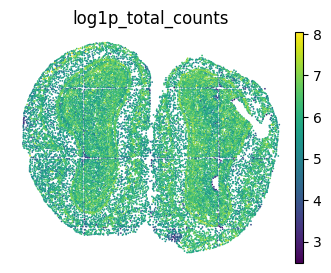

In [4]:
sc.pl.embedding(adata_raw, basis="spatial", color = "log1p_total_counts", frameon=False)

## Preprocess the data

In [5]:
# Preprocess the data 
sc.pp.filter_genes(adata_raw, min_cells=50)
sc.pp.normalize_total(adata_raw, target_sum=1e4)
sc.pp.log1p(adata_raw)

## Run CadaST

In [6]:
n_top = 2000 # n_top SVG 
n_jobs = 16 # parallel jobs 
model = CadaST(
    adata_raw,
    n_top=n_top,
    n_jobs=n_jobs,
    seed = seed #fix the random seed
)
adata_fit = model.fit()
adata_fit 

Constructing KNN
Initializing neighbor correlation matrix 
Initialized model with beta: 10, alpha: 0.6, theta: 0.2
Filtering genes with top 2000 SVG features
Start CadaST model fitting


100%|██████████| 2000/2000 [01:04<00:00, 31.08it/s] 


AnnData object with n_obs × n_vars = 19109 × 2000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'labels'

## Clustering using mclust and spatial domain visulization 

In [7]:
clustering(adata=adata_fit, n_clusters=7, seed = seed )
adata_raw.obsm["X_pca"] = adata_fit.obsm["X_pca"]

Clustering using mclust


R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



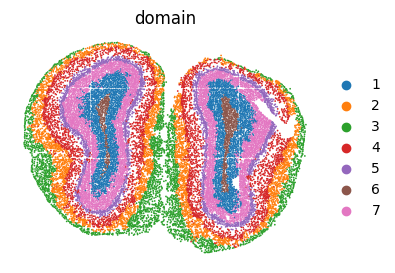

In [8]:
sc.pl.embedding(adata_fit, basis="spatial", color="domain", frameon=False)

In [ ]:
def cal_silhouette_score(adata: sc.AnnData, label_key: str):
    from sklearn.metrics import silhouette_score

    X = adata.obsm["X_pca"]
    print(X.shape)
    labels = adata.obs[label_key]
    labels = labels.astype("category").cat.codes
    sil_score = silhouette_score(X, labels)
    return sil_score


def cal_neighborhood_consistancy_score(adata: sc.AnnData, label_key: str, kneighbors: int = 16):
    """
    Calculate label-wise correlation between spot's expression and the neiborhood k's mean
    """
    from scipy.stats import pearsonr
    from sklearn.neighbors import kneighbors_graph

    labels = adata.obs[label_key]
    unique_labels = labels.unique()
    total_pearson = []
    for label in unique_labels:
        adata_sub = adata[adata.obs[label_key] == label].copy()
        coordinates = adata_sub.obsm["spatial"]
        graph = kneighbors_graph(coordinates, kneighbors, mode="connectivity", include_self=False)
        X = np.ndarray(adata_sub.X) if not isinstance(adata_sub.X, np.ndarray) else adata_sub.X
        neighbor_mean = graph.dot(X) / kneighbors
        pearsons = [pearsonr(X[i, :], neighbor_mean[i, :])[0] for i in range(X.shape[0])]
        total_pearson.append(np.asarray(pearsons).mean())
    return np.mean(total_pearson)


In [10]:
adata_raw.obs["domain"] = adata_fit.obs["domain"]
## Calculate the metrics using raw data metrics
sil_score = cal_silhouette_score(adata_raw, label_key="domain")
ncs_score = cal_neighborhood_consistancy_score(adata_raw, label_key="domain", kneighbors=16)
print(f"Silhouette score: {sil_score:.4f}, Neighborhood consistancy score: {ncs_score:.4f}")

(19109, 15)
Silhouette score: 0.1666, Neighborhood consistancy score: 0.1929
